In [1]:
data_dir = "/home/eagiem/resilient-miniMD/miniMD/build-tmr-kokkos-4.7.01-deprecated/random-injection-100-timesteps"
data_fname_r100 = "parsed-resminimd-random-100-timesteps.txt"
data_fname_m100 = "parsed-minimd-random-100-timesteps.txt"
data_dir1 = "/home/eagiem/resilient-miniMD/miniMD/build-tmr-kokkos-4.7.01-deprecated/random-injection-1000-timesteps"
data_fname_r1000 = "parsed-resminimd-random-1000-timesteps.txt"
data_fname_m1000 = "parsed-minimd-random-1000-timesteps.txt"

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

In [3]:
names = [
    "prog",
    "runidx",
    "nthreads",
    "ntimesteps",
    "nerrors",
    "t_initial_integrate",
    "t_final_integrate",
    "t_injection",
    "t_total_integrate",
    "t_force",
    "total_t",
]
df0 = pd.read_csv(
    f"{data_dir}/{data_fname_r100}", names=names, sep=",", index_col=False
)
df1 = pd.read_csv(
    f"{data_dir}/{data_fname_m100}", names=names, sep=",", index_col=False
)

df3 = pd.read_csv(
    f"{data_dir1}/{data_fname_r1000}", names=names, sep=",", index_col=False
)
df4 = pd.read_csv(
    f"{data_dir1}/{data_fname_m1000}", names=names, sep=",", index_col=False
)

df = pd.concat([df0, df1], axis=0, ignore_index=True)
#pd.set_option('display.max_rows', None)
df_1000 = pd.concat([df3, df4], axis=0, ignore_index=True)


df

,prog,runidx,nthreads,ntimesteps,nerrors,t_initial_integrate,t_final_integrate,t_injection,t_total_integrate,t_force,total_t
0,minimd_resil,1,1,100,201.0,0.969487,1.124420,1274442.0,2.093900,6.078900,9.422114
1,minimd_resil,2,1,100,201.0,0.964532,1.127110,1054728.0,2.091640,6.082400,9.419060
2,minimd_resil,3,1,100,201.0,0.972444,1.117630,1071421.0,2.090070,6.081870,9.411988
3,minimd_resil,4,1,100,201.0,0.968040,1.120550,1171938.0,2.088590,6.085420,9.427760
4,minimd_resil,5,1,100,201.0,0.963464,1.122940,1111767.0,2.086400,6.084370,9.413449
...,...,...,...,...,...,...,...,...,...,...,...
135,minimd,6,56,100,NaN,0.008384,0.006415,NaN,0.014799,0.519933,0.662436
136,minimd,7,56,100,NaN,0.008095,0.006162,NaN,0.014257,0.514735,0.654015
137,minimd,8,56,100,NaN,0.007866,0.006353,NaN,0.014219,0.507321,0.645934
138,minimd,9,56,100,NaN,0.007770,0.005803,NaN,0.013573,0.511017,0.647280


In [4]:
total_t_avg=df.groupby(['prog','nthreads'])['total_t'].mean()
force_avg=df.groupby(['prog','nthreads'])['t_force'].mean()
integration_avg=df.groupby(['prog','nthreads'])['t_total_integrate'].mean()
overhead_avg=df.groupby(['prog','nthreads'])['t_injection'].mean()

averages = df.groupby(['prog','nthreads']).agg(
    {'total_t': 'mean',
     't_force': 'mean',
     't_total_integrate': 'mean',
     't_injection': 'mean'}
).reset_index()

averages = averages.replace('NaN', 0)
averages['t_injection']=averages['t_injection'].div(1e9)

averages

,prog,nthreads,total_t,t_force,t_total_integrate,t_injection
0,minimd,1,7.476784,6.087866,0.131597,NaN
1,minimd,2,7.070747,6.318851,0.086814,NaN
2,minimd,4,3.699890,3.281700,0.048829,NaN
3,minimd,8,2.098719,1.844880,0.028606,NaN
4,minimd,16,1.176183,1.008382,0.018616,NaN
5,minimd,28,0.761376,0.628303,0.013218,NaN
6,minimd,56,0.652081,0.512894,0.014207,NaN
7,minimd_resil,1,9.423087,6.082641,2.095318,0.001144
8,minimd_resil,2,20.823609,18.884430,1.273815,0.000650
9,minimd_resil,4,11.058497,9.831892,0.856346,0.000671


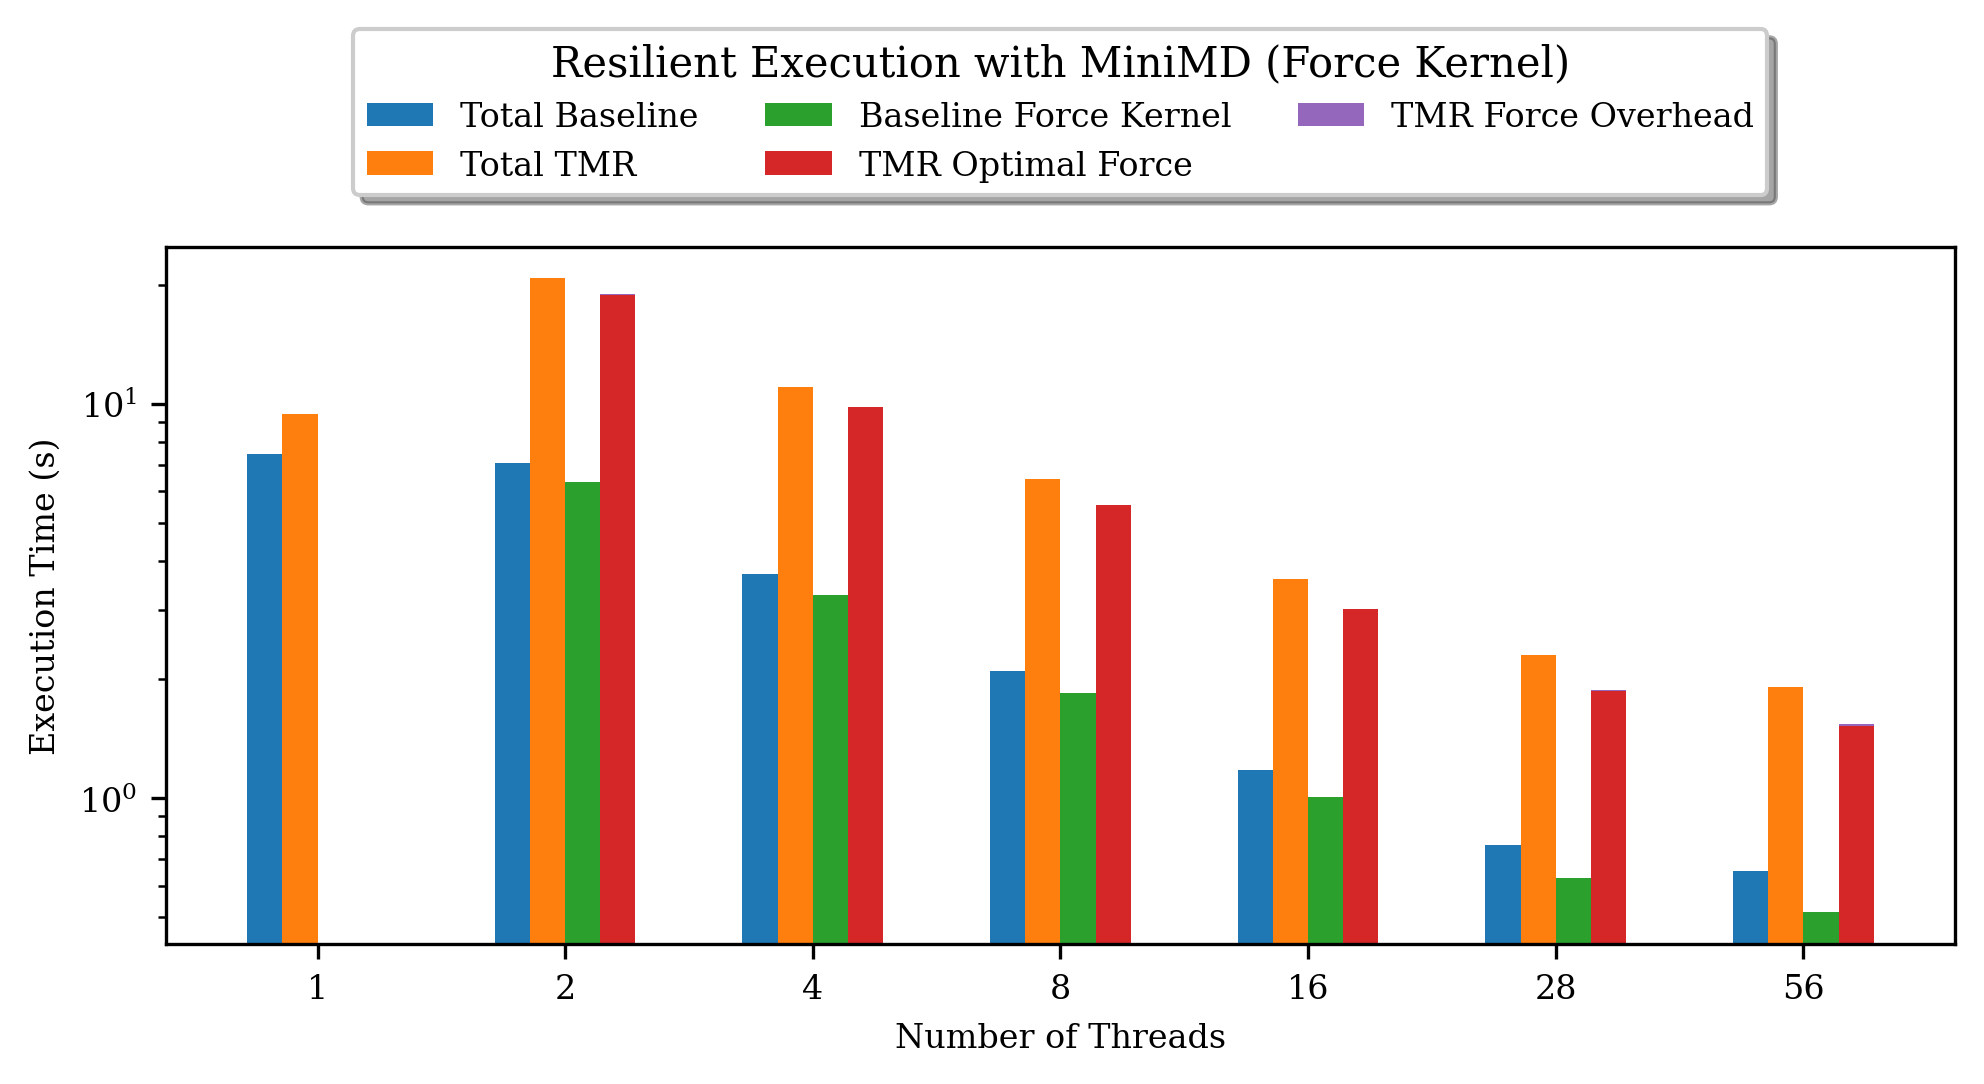

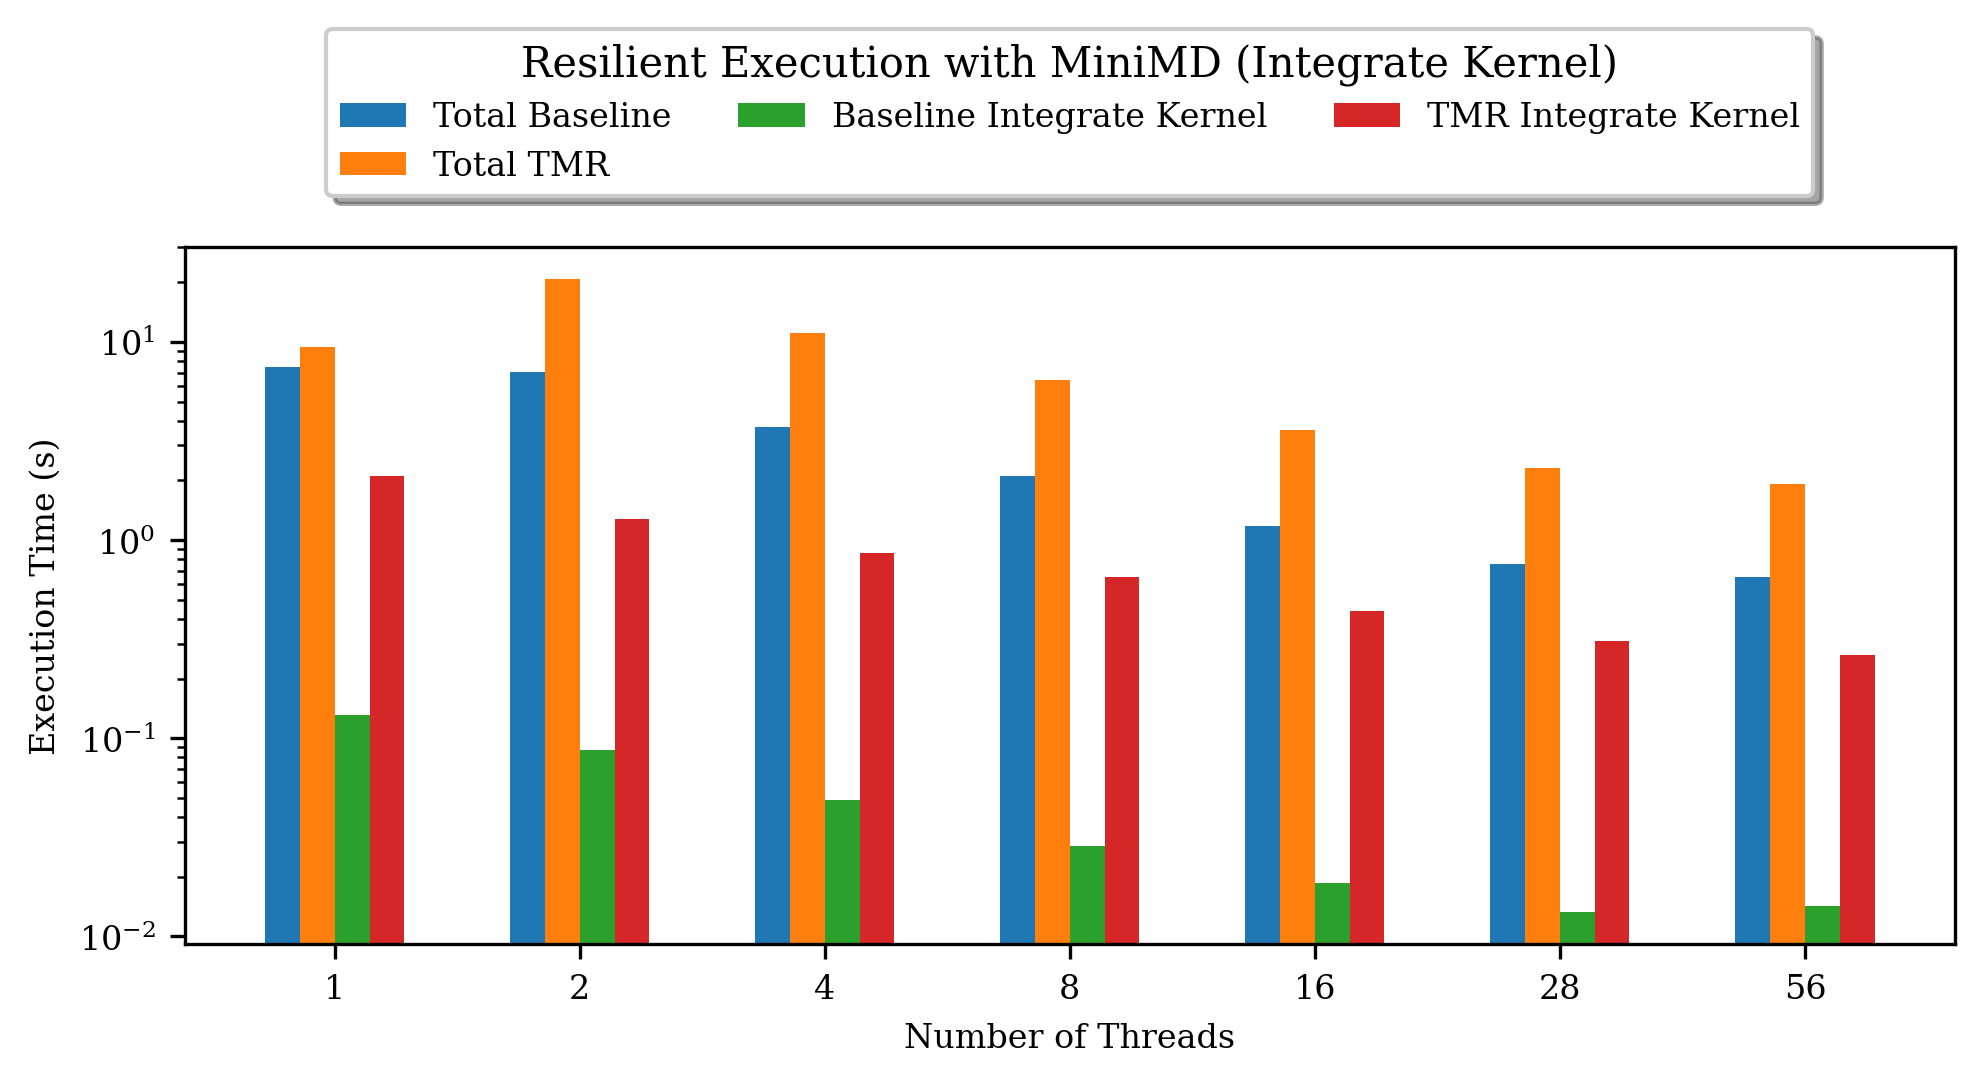

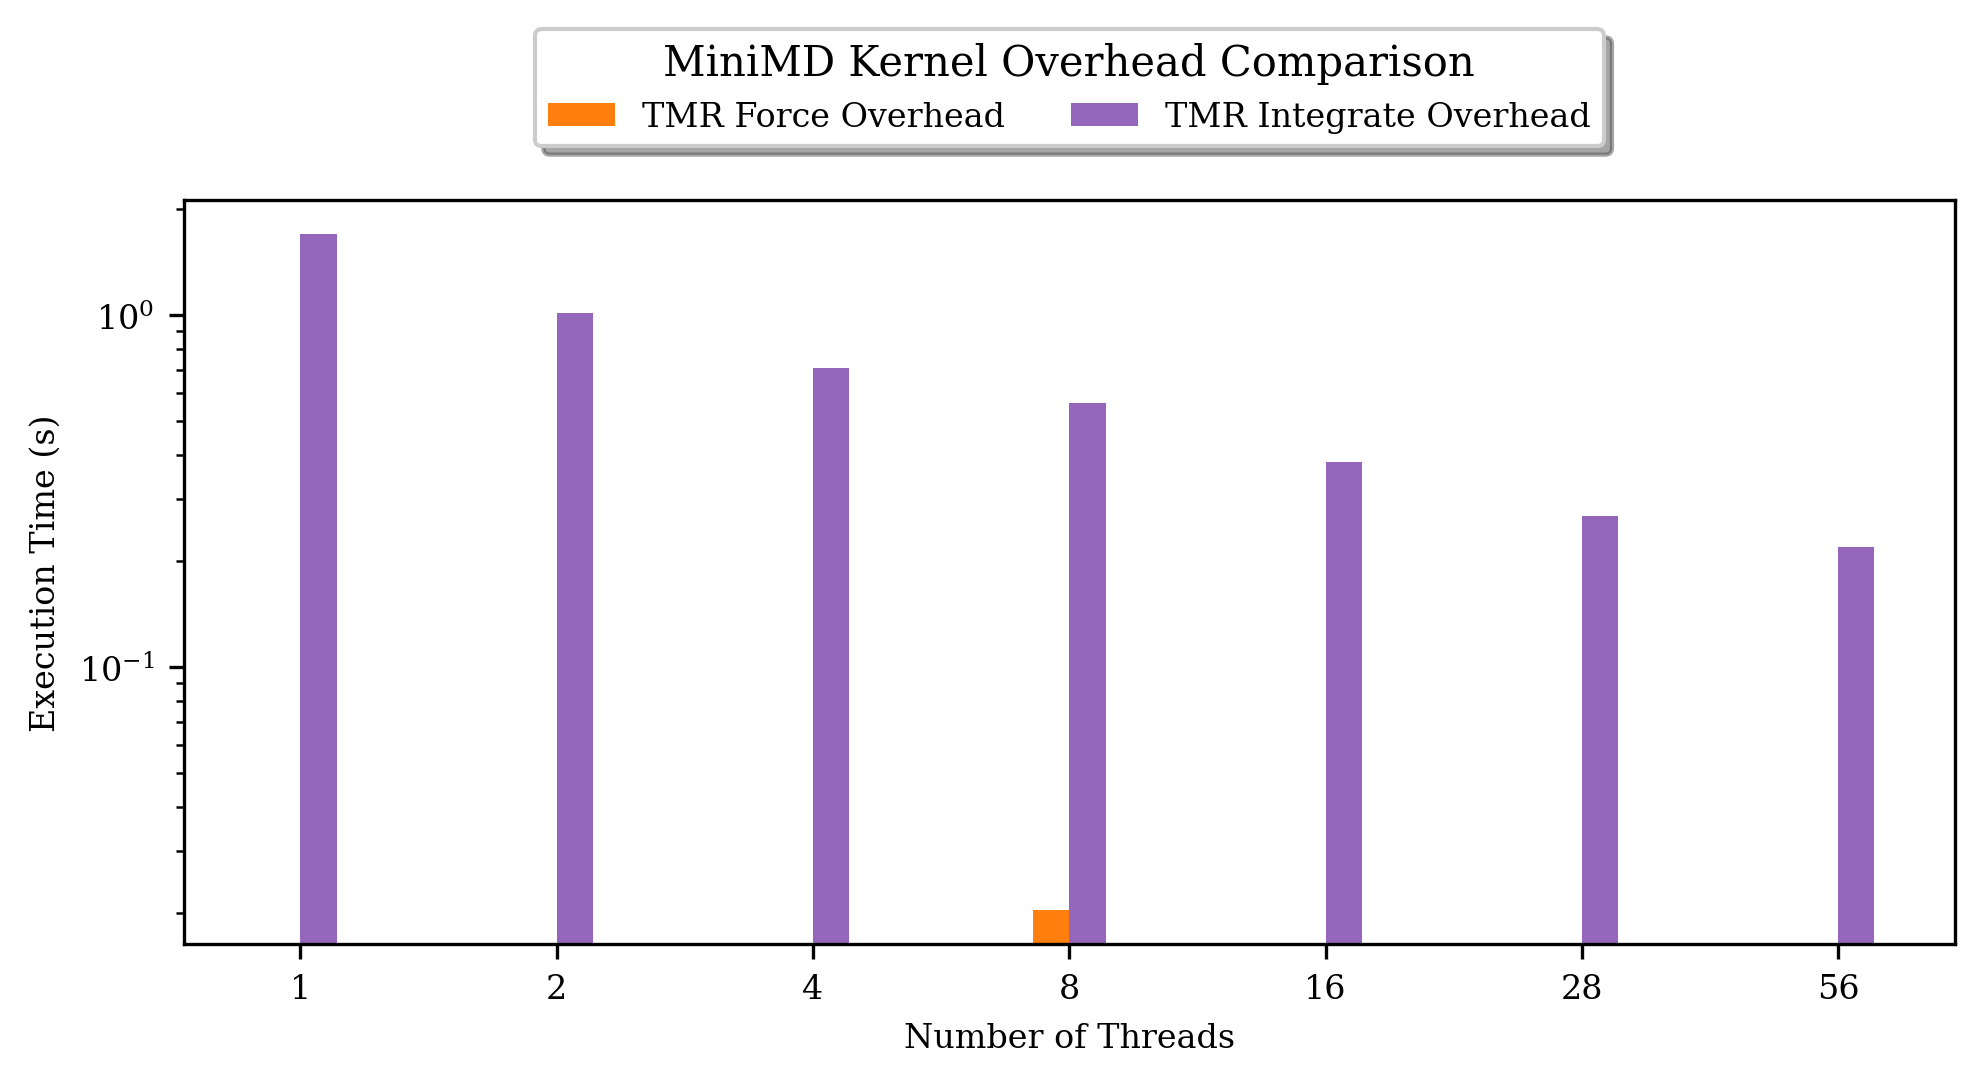

In [7]:
#plt.figure(figsize=(6, 3))
#fig_width = 3.39 #for doc-type paper, otherwise 8
#fig_height = fig_width * (math.sqrt(5) - 1.0) *0.5 #golden ratio
fig_width = 6.5
fig_height = 3.5
fontsize= 8 #to match latex paper doc font size, may also need to be 10, otherwise 14
linewidth = 1.0 #otherwise 5.0 if not latex paper doc
dpi = 300 #for latex paper otherwise 300

params = {
	"font.family":"serif",
	"pgf.rcfonts":False,
	'axes.labelsize': fontsize,
	'axes.titlesize': fontsize,
	'legend.fontsize': fontsize,
	'xtick.labelsize': fontsize,
	'ytick.labelsize': fontsize,
	'figure.figsize': [fig_width, fig_height],
	'figure.autolayout': True,
	'figure.dpi': dpi,
	'lines.linewidth': linewidth
}

mpl.rcParams.update(params)


new_value = 0
temp = pd.Series([new_value], name='t_force')

baseline = averages.loc[0:6, 'total_t']
tmr = averages.loc[7:13, 'total_t']
baseline_force = averages.loc[1:6, 't_force']
baseline_force = pd.concat([temp, baseline_force]).reset_index(drop=True)
tmr_force = averages.loc[8:13, 't_force']
tmr_force = pd.concat([temp, tmr_force]).reset_index(drop=True)
baseline_integrate = averages.loc[0:6, 't_total_integrate']
tmr_integrate = averages.loc[7:13, 't_total_integrate']
#tmr_injection = averages.loc[7:13, 't_injection']
blank = [0,0,0,0,0,0,0]


baseline_force_vals = baseline_force.values
tmr_force_vals = tmr_force.values
baseline_integrate_vals = baseline_integrate.values
tmr_integrate_vals = tmr_integrate.values

tmr_opt = 3 * baseline_force_vals
tmr_overhead = tmr_force_vals - tmr_opt

int_opt = 3 * baseline_integrate_vals
int_overhead = tmr_integrate_vals - int_opt

w = 0.142
x_labels = ["1", "2", "4", "8", "16", "28", "56"] #x labels

bar1 = np.arange(len(x_labels))
bar2 = [ i + w for i in bar1]
bar3 = [ i + (2*w) for i in bar1]
bar4 = [ i + (3*w) for i in bar1]
bar5 = [ i + (4*w) for i in bar1]
bar6 = [ i + (5*w) for i in bar1]
bar7 = [ i + (6*w) for i in bar1]
#bar8 = [ i + (7*w) for i in bar1]

#============== FULL GRAPH ============

#ax.bar(bar1, baseline, w, label="Total Baseline")
#ax.bar(bar2, tmr, w, label="Total TMR")
#ax.bar(bar3, baseline_force, w, label="Baseline Force Kernel")

#ax.bar(bar4, tmr_opt, w, label="TMR Optimal Force")
#ax.bar(bar4, tmr_overhead, w, bottom=tmr_opt, label="TMR Force Overhead")

#ax.bar(bar5, baseline_integrate, w, label="Baseline Integrate Kernel")
#ax.bar(bar6, tmr_integrate, w, label="TMR Integrate Kernel")
#plt.bar(bar7, tmr_injection, w, label="Error Injection Time")
#ax.bar(bar7, blank, w, label="_")

#ax.set_xlabel('Number of Threads')
#ax.set_ylabel('Execution Time (s)')
#ax.set_yscale('log')
#ax.set_xticks(bar1 + 1.5 * w)
#ax.set_xticklabels(x_labels)

#ax.legend(title='Resilient Execution with MiniMD', bbox_to_anchor=(0.5, 1.05), loc='lower center', ncol=3, fancybox=True, shadow=True)

#plt.savefig("openmp_minimd.pdf")
#plt.show()

# ========
# JUST FORCE
# =======
fig, ax = plt.subplots(constrained_layout=True)

#baslines plus force
ax.bar(bar1, baseline, w, label="Total Baseline")
ax.bar(bar2, tmr, w, label="Total TMR")
ax.bar(bar3, baseline_force, w, label="Baseline Force Kernel")
ax.bar(bar4, tmr_opt, w, label="TMR Optimal Force")
ax.bar(bar4, tmr_overhead, w, bottom=tmr_opt, label="TMR Force Overhead")

ax.set_xlabel('Number of Threads')
ax.set_ylabel('Execution Time (s)')
ax.set_yscale('log')

# xticks centering adjust
ax.set_xticks(bar1 + 1.5 * w)
ax.set_xticklabels(x_labels)

ax.legend(title='Resilient Execution with MiniMD (Force Kernel)', bbox_to_anchor=(0.5, 1.05), loc='lower center', ncol=3, fancybox=True, shadow=True)
plt.savefig("openmp_minimd_force.pdf")
plt.show()
plt.close(fig)

# ========
# JUST INTEGRATION
# =======
fig, ax = plt.subplots(constrained_layout=True)

#baslines plus integration
ax.bar(bar1, baseline, w, label="Total Baseline")
ax.bar(bar2, tmr, w, label="Total TMR")
ax.bar(bar3, baseline_integrate, w, label="Baseline Integrate Kernel")
ax.bar(bar4, tmr_integrate, w, label="TMR Integrate Kernel")

ax.set_xlabel('Number of Threads')
ax.set_ylabel('Execution Time (s)')
ax.set_yscale('log')

# xticks centering adjust
ax.set_xticks(bar1 + 1.5 * w)
ax.set_xticklabels(x_labels)

ax.legend(title='Resilient Execution with MiniMD (Integrate Kernel)', bbox_to_anchor=(0.5, 1.05), loc='lower center', ncol=3, fancybox=True, shadow=True)
plt.savefig("openmp_minimd_integrate.pdf")
plt.show()
plt.close(fig)

# ========
# OVERHEADS
# =======
fig, ax = plt.subplots(constrained_layout=True)

#overheads
ax.bar(bar1, tmr_overhead, w, label="TMR Force Overhead", color='tab:orange')
ax.bar(bar2, int_overhead, w, label="TMR Integrate Overhead",color='tab:purple')


ax.set_xlabel('Number of Threads')
ax.set_ylabel('Execution Time (s)')
ax.set_yscale('log')

# xticks centering adjust
ax.set_xticks(bar1 + 0.5 * w)
ax.set_xticklabels(x_labels)

ax.legend(title='MiniMD Kernel Overhead Comparison', bbox_to_anchor=(0.5, 1.05), loc='lower center', ncol=3, fancybox=True, shadow=True)
plt.savefig("openmp_minimd_overhead.pdf")
plt.show()
plt.close(fig)


In [6]:
df2 = pd.read_csv(
    f"{data_dir1}/{data_fname2}", names=names, sep=",", index_col=False
)
df3 = pd.read_csv(
    f"{data_dir1}/{data_fname3}", names=names, sep=",", index_col=False
)

df1000 = pd.concat([df2, df3], axis=0, ignore_index=True)

#df1000

tmr_overhead

NameError: name 'data_fname2' is not defined

In [ ]:
cuda_dir = "/home/eagiem/resilient-miniMD/miniMD/build-cuda-debug/random-injection"
cuda_fres_force = "parsed-force-10000.txt"
cuda_fres_int = "parsed-integrate-1000.txt"
cuda_fmini_force = "total-miniMD-10000-rand.txt"
cuda_fmini_int = "total-miniMD-1000-rand.txt"

In [ ]:
n_f = [
    "prog",
    "runidx",
    "ngpu",
    "ntimesteps",
    "t_injection",
    "t_force",
    "total_t",
]

n_i = [
    "prog",
    "runidx",
    "ngpu",
    "ntimesteps",
    "t_injection",
    "t_initial_integrate",
    "t_final_integrate",
    "t_total_integrate",
    "total_t",
]
drf_in = pd.read_csv(
    f"{cuda_dir}/{cuda_fres_force}", names=n_f, sep=",", index_col=False
)
drf = drf_in.iloc[:-50]
dmf = pd.read_csv(
    f"{cuda_dir}/{cuda_fmini_force}", names=n_f, sep=",", index_col=False
)
dforce = pd.concat([drf, dmf], axis=0, ignore_index=True)
#pd.set_option('display.max_rows', None)

#dforce

In [ ]:
total_t_avgf=dforce.groupby(['prog','ngpu'])['total_t'].mean()
force_avgf=dforce.groupby(['prog','ngpu'])['t_force'].mean()
overhead_avgf=dforce.groupby(['prog','ngpu'])['t_injection'].mean()

averagesf = dforce.groupby(['prog','ngpu']).agg(
    {'total_t': 'mean',
     't_force': 'mean',
     't_injection': 'mean'}
).reset_index()

#averagesf = averagesf.replace('NaN', 0)
averagesf['t_injection']=averagesf['t_injection'].div(1e9)

averagesf

In [ ]:
#plt.figure(figsize=(6, 3))
#fig_width = 3.39 #for doc-type paper, otherwise 8
#fig_height = fig_width * (math.sqrt(5) - 1.0) *0.5 #golden ratio
fig_width = 3.25
fig_height = 2.5
fontsize= 8 #to match latex paper doc font size, may also need to be 10, otherwise 14
linewidth = 1.0 #otherwise 5.0 if not latex paper doc
dpi = 300 #for latex paper otherwise 300
fig, ax = plt.subplots(constrained_layout=True)

params = {
	"font.family":"serif",
	"pgf.rcfonts":False,
	'axes.labelsize': fontsize,
	'axes.titlesize': fontsize,
	'legend.fontsize': fontsize,
	'xtick.labelsize': fontsize,
	'ytick.labelsize': fontsize,
	'figure.figsize': [fig_width, fig_height],
	'figure.autolayout': True,
	'figure.dpi': dpi,
	'lines.linewidth': linewidth
}

mpl.rcParams.update(params)

baseline = averagesf.loc[0:4, 'total_t']
cuda = averagesf.loc[5:9, 'total_t']
baseline_f_k = averagesf.loc[0:4, 't_force']
cuda_f_k = averagesf.loc[5:9, 't_force']
baseline_inj = averagesf.loc[0:4, 't_injection']
cuda_inj = averagesf.loc[5:9, 't_injection']

baseline_force = baseline_f_k - baseline_inj
cuda_force = cuda_f_k - cuda_inj
blank = [0,0,0,0,0]

w = 0.2
x_labels = ["1", "2", "4", "8", "16"] #x labels

bar1 = np.arange(len(x_labels))
bar2 = [ i + w for i in bar1]
bar3 = [ i + (2*w) for i in bar1]
bar4 = [ i + (3*w) for i in bar1]
bar5 = [ i + (4*w) for i in bar1]

ax.bar(bar1, baseline, w, label="Total Baseline")
ax.bar(bar2, cuda, w, label="Total TMR")
ax.bar(bar3, baseline_force, w, label="Baseline Force Kernel")
ax.bar(bar4, cuda_force, w, label="TMR Force Kernel")
ax.bar(bar5, blank, w, label="_")

ax.set_xlabel('Number of GPUs')
ax.set_ylabel('Execution Time (s)')
#ax.xlabel('Number of Threads') #Add x-label to axis
#ax.ylabel('Execution Time (s)') #Add y-label to axis
#ax.yscale('log')
ax.set_yscale('log')
#plt.title("Resilient Execution with MiniMD") #Add title to the axes
#ax.xticks(bar1 + 1.5 * w, x) #Display the xticks label
ax.set_xticks(bar1 + 1.5 * w)
ax.set_xticklabels(x_labels)

ax.legend(title='Resilient MiniMD, CUDA Force Kernel', bbox_to_anchor=(0.5, 1.05), loc='lower center', ncol=2, fancybox=True, shadow=True)
#ax.tight_layout(rect=[0, 0, 1, 1])
#ax.set_title("Resilient Execution with MiniMD")
#plt.legend()
#plt.tight_layout(rect=[0, 0, 1, 0.5])
#plt.figure(figsize=(10, 10))

plt.savefig("cuda_force.pdf")
plt.show()

In [ ]:
drin = pd.read_csv(
    f"{cuda_dir}/{cuda_fres_int}", names=n_i, sep=",", index_col=False
)
dmin = pd.read_csv(
    f"{cuda_dir}/{cuda_fmini_int}", names=n_i, sep=",", index_col=False
)
dint = pd.concat([drin, dmin], axis=0, ignore_index=True)

In [ ]:
dint['total_t']=pd.to_numeric(dint['total_t'], errors='coerce')
dint['total_t'] = dint['total_t'].ffill()


In [ ]:
total_t_avgi=dint.groupby(['prog','ngpu'])['total_t'].mean()
i_total_avgi=dint.groupby(['prog','ngpu'])['t_total_integrate'].mean()
i_final_avgi=dint.groupby(['prog','ngpu'])['t_final_integrate'].mean()
i_initial_avgi=dint.groupby(['prog','ngpu'])['t_initial_integrate'].mean()
overhead_avgi=dint.groupby(['prog','ngpu'])['t_injection'].mean()

averagesi = dint.groupby(['prog','ngpu']).agg(
    {'total_t': 'mean',
     't_initial_integrate': 'mean',
     't_final_integrate': 'mean',
     't_total_integrate': 'mean',
     't_injection': 'mean'}
).reset_index()

#averagesf = averagesf.replace('NaN', 0)
averagesi['t_injection']=averagesi['t_injection'].div(1e9)

averagesi

In [ ]:
#plt.figure(figsize=(6, 3))
#fig_width = 3.39 #for doc-type paper, otherwise 8
#fig_height = fig_width * (math.sqrt(5) - 1.0) *0.5 #golden ratio
fig_width = 3.25
fig_height = 2.5
fontsize= 8 #to match latex paper doc font size, may also need to be 10, otherwise 14
linewidth = 1.0 #otherwise 5.0 if not latex paper doc
dpi = 300 #for latex paper otherwise 300
fig, ax = plt.subplots(constrained_layout=True)

params = {
	"font.family":"serif",
	"pgf.rcfonts":False,
	'axes.labelsize': fontsize,
	'axes.titlesize': fontsize,
	'legend.fontsize': fontsize,
	'xtick.labelsize': fontsize,
	'ytick.labelsize': fontsize,
	'figure.figsize': [fig_width, fig_height],
	'figure.autolayout': True,
	'figure.dpi': dpi,
	'lines.linewidth': linewidth
}

mpl.rcParams.update(params)

baseline = averagesi.loc[0:4, 'total_t']
cuda = averagesi.loc[5:9, 'total_t']
baseline_i_k = averagesi.loc[0:4, 't_total_integrate']
cuda_i_k = averagesi.loc[5:9, 't_total_integrate']
baseline_inj = averagesi.loc[0:4, 't_injection']
cuda_inj = averagesi.loc[5:9, 't_injection']

baseline_int = baseline_i_k - baseline_inj
cuda_int = cuda_i_k - cuda_inj
blank = [0,0,0,0,0]

w = 0.2
x_labels = ["1", "2", "4", "8", "16"] #x labels

bar1 = np.arange(len(x_labels))
bar2 = [ i + w for i in bar1]
bar3 = [ i + (2*w) for i in bar1]
bar4 = [ i + (3*w) for i in bar1]
bar5 = [ i + (4*w) for i in bar1]

ax.bar(bar1, baseline, w, label="Total Baseline")
ax.bar(bar2, cuda, w, label="Total TMR")
ax.bar(bar3, baseline_int, w, label="Baseline Integration Kernel")
ax.bar(bar4, cuda_int, w, label="TMR Integration Kernel")
ax.bar(bar5, blank, w, label="_")

ax.set_xlabel('Number of GPUs')
ax.set_ylabel('Execution Time (s)')
#ax.xlabel('Number of Threads') #Add x-label to axis
#ax.ylabel('Execution Time (s)') #Add y-label to axis
#ax.yscale('log')
ax.set_yscale('log')
#plt.title("Resilient Execution with MiniMD") #Add title to the axes
#ax.xticks(bar1 + 1.5 * w, x) #Display the xticks label
ax.set_xticks(bar1 + 1.5 * w)
ax.set_xticklabels(x_labels)

ax.legend(title='Resilient MiniMD, CUDA Integration Kernel', bbox_to_anchor=(0.5, 1.05), loc='lower center', ncol=2, fancybox=True, shadow=True)
#ax.tight_layout(rect=[0, 0, 1, 1])
#ax.set_title("Resilient Execution with MiniMD")
#plt.legend()
#plt.tight_layout(rect=[0, 0, 1, 0.5])
#plt.figure(figsize=(10, 10))

plt.savefig("cuda_int.pdf")
plt.show()